# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

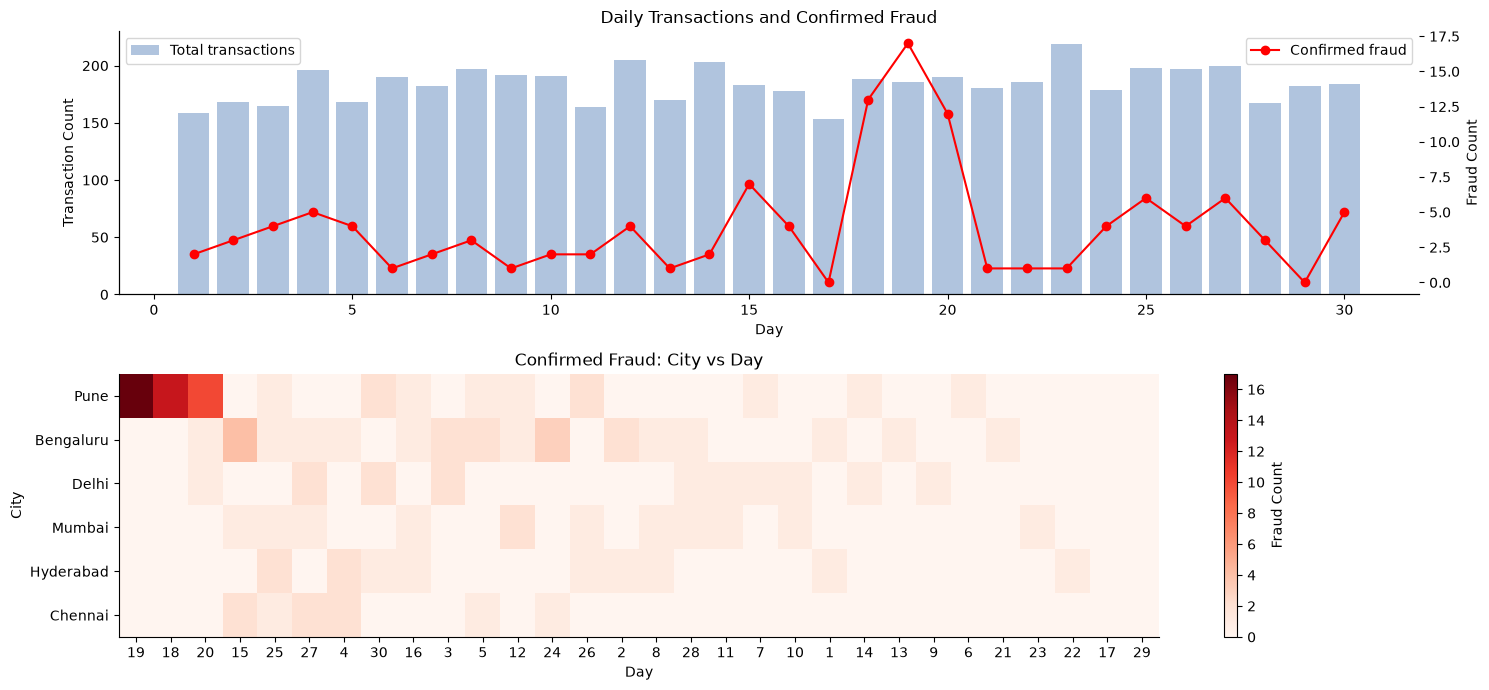

Top 10 City-Day Fraud Combinations:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  2       2
           5       2
Pune       30      2
dtype: int64


In [2]:

fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1: Daily transaction counts and confirmed fraud
daily = tx.groupby("day").agg(
    transactions=("txn_id", "count"),
    fraud=("is_fraud", "sum")
)

axes[0].bar(
    daily.index,
    daily["transactions"],
    color="lightsteelblue",
    label="Total transactions"
)

ax2 = axes[0].twinx()

ax2.plot(
    daily.index,
    daily["fraud"],
    color="red",
    marker="o",
    label="Confirmed fraud"
)

axes[0].set_title("Daily Transactions and Confirmed Fraud")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Transaction Count")
ax2.set_ylabel("Fraud Count")

axes[0].legend(loc="upper left")
ax2.legend(loc="upper right")

# TODO 2: City x Day fraud-count matrix
heat = tx.pivot_table(
    index="city",
    columns="day",
    values="is_fraud",
    aggfunc="sum",
    fill_value=0
)

# Reorder cities and days by their total fraud counts
heat = heat.loc[
    heat.sum(axis=1).sort_values(ascending=False).index,
    heat.sum(axis=0).sort_values(ascending=False).index
]

im = axes[1].imshow(
    heat,
    cmap="Reds",
    aspect="auto"
)

axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)

axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns)

axes[1].set_title("Confirmed Fraud: City vs Day")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("City")

plt.colorbar(im, ax=axes[1], label="Fraud Count")

plt.tight_layout()
plt.show()

# TODO 3: Print cells with the most fraud
top_cells = (
    heat.stack()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 City-Day Fraud Combinations:")
print(top_cells)


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_An alert list sorted by detector score would show individual suspicious transactions but would not reveal the overall distribution of fraud across cities and days. The overview heatmap exposed a concentration of confirmed fraud in Pune between days 18 and 20. This uses the lecture concept of visual pattern detection through a reordered matrix (Slide 39), helping identify unusual clusters that may otherwise remain hidden.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

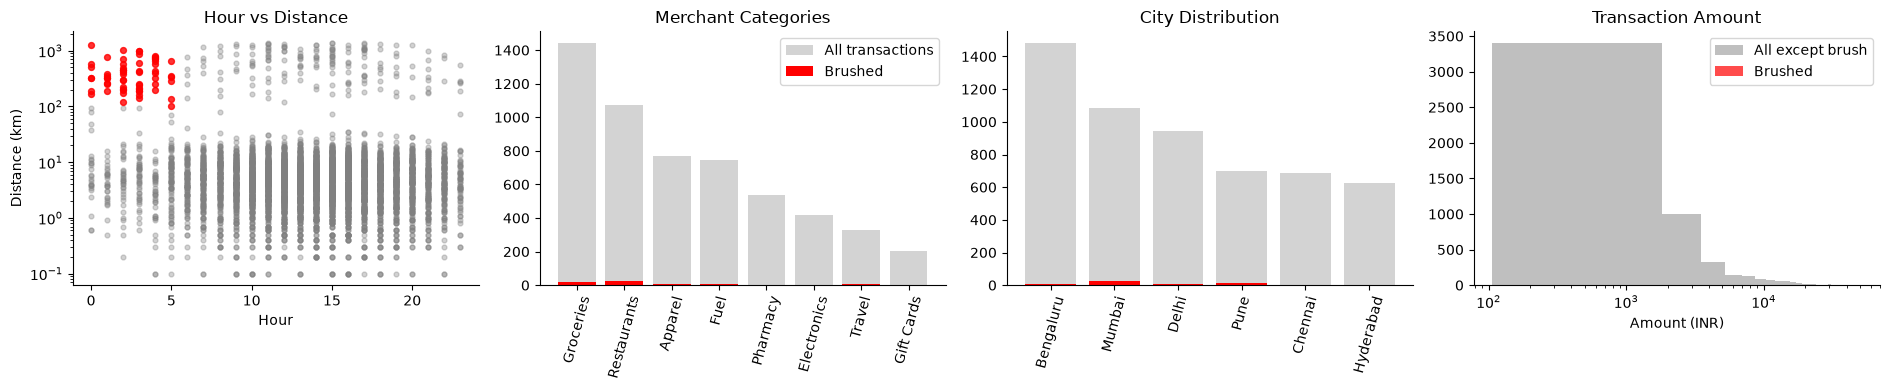

Transactions in brush: 61
Fraud rate inside brush: 86.89%
Overall fraud rate: 2.17%
Share of all fraud captured: 44.17%


In [3]:

# TODO 1: Define the brush
brush = (
    (tx["night"] == True) &
    (tx["distance_from_home_km"] > 100)
)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2(a): Hour vs distance scatter
axes[0].scatter(
    tx.loc[~brush, "hour"],
    tx.loc[~brush, "distance_from_home_km"],
    color="grey",
    alpha=0.35,
    s=12
)

axes[0].scatter(
    tx.loc[brush, "hour"],
    tx.loc[brush, "distance_from_home_km"],
    color="red",
    alpha=0.8,
    s=18
)

axes[0].set_yscale("log")
axes[0].set_title("Hour vs Distance")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance (km)")

# TODO 2(b): Merchant category counts
cat_all = tx["merchant_category"].value_counts()
cat_brush = tx.loc[brush, "merchant_category"].value_counts()

axes[1].bar(
    cat_all.index,
    cat_all.values,
    color="lightgrey",
    label="All transactions"
)

axes[1].bar(
    cat_brush.index,
    cat_brush.reindex(cat_all.index, fill_value=0),
    color="red",
    label="Brushed"
)

axes[1].set_title("Merchant Categories")
axes[1].tick_params(axis="x", rotation=75)
axes[1].legend()

# TODO 2(c): City counts
city_all = tx["city"].value_counts()
city_brush = tx.loc[brush, "city"].value_counts()

axes[2].bar(
    city_all.index,
    city_all.values,
    color="lightgrey"
)

axes[2].bar(
    city_brush.index,
    city_brush.reindex(city_all.index, fill_value=0),
    color="red"
)

axes[2].set_title("City Distribution")
axes[2].tick_params(axis="x", rotation=75)

# TODO 2(d): Amount histogram
axes[3].hist(
    tx.loc[~brush, "amount_inr"],
    bins=30,
    color="grey",
    alpha=0.5,
    label="All except brush"
)

axes[3].hist(
    tx.loc[brush, "amount_inr"],
    bins=30,
    color="red",
    alpha=0.7,
    label="Brushed"
)

axes[3].set_xscale("log")
axes[3].set_title("Transaction Amount")
axes[3].set_xlabel("Amount (INR)")
axes[3].legend()

plt.tight_layout()
plt.show()

# TODO 3: Calculate brush statistics
n_brushed = brush.sum()

fraud_rate_brush = tx.loc[brush, "is_fraud"].mean()

fraud_rate_overall = tx["is_fraud"].mean()

fraud_captured = (
    tx.loc[brush, "is_fraud"].sum() /
    tx["is_fraud"].sum()
)

print(f"Transactions in brush: {n_brushed}")
print(f"Fraud rate inside brush: {fraud_rate_brush:.2%}")
print(f"Overall fraud rate: {fraud_rate_overall:.2%}")
print(f"Share of all fraud captured: {fraud_captured:.2%}")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_Although the night-time, far-from-home brush has a high fraud rate of 86.89%, it captures only 44.17% of all confirmed fraud cases. Therefore, relying exclusively on this rule would miss 55.83% of fraud. The city-linked view helps reveal that Pune has the largest overall concentration of confirmed fraud, indicating that investigators should also investigate geographical patterns rather than relying only on transaction characteristics.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:

big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Measure filter time (best of 5 runs)
times = []

for _ in range(5):
    start = time.perf_counter()

    result = big[
        (big["detector_score"] >= 0.6) &
        (big["amount_inr"] > 3000)
    ]

    elapsed = time.perf_counter() - start
    times.append(elapsed)

best_s = min(times)

# TODO 2: Per-item cost and maximum rows within 0.1 seconds
per_item_us = (best_s / len(big)) * 1_000_000

max_rows = 0.1 / (best_s / len(big))

# TODO 3: Estimate 50 million rows
t_50m = (50_000_000 * best_s) / len(big)

skip_pct = (1 - (0.1 / t_50m)) * 100

print(
    f"{len(big):,} rows in {best_s*1000:.2f} ms "
    f"-> {per_item_us:.4f} us/row "
    f"-> max {max_rows:,.0f} rows in 0.1 s"
)

print(
    f"50M rows -> {t_50m:.2f} s; "
    f"must skip {skip_pct:.1f}% of rows to stay under 0.1 s"
)


1,004,640 rows in 15.77 ms -> 0.0157 us/row -> max 6,372,072 rows in 0.1 s
50M rows -> 0.78 s; must skip 87.3% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_One useful reduce technique is sampling or pre-aggregation. Instead of filtering all 50 million individual transactions, the system can display representative samples or aggregated transaction counts. This reduces the processing workload and helps the slider remain responsive. However, the analyst loses access to some individual transaction details and may miss rare fraud cases present in the omitted data.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

Capacity-constrained choice:
threshold      0.800000
alerts       144.000000
TP            84.000000
FP            60.000000
FN            36.000000
precision      0.583333
recall         0.700000
F1             0.636364
Name: 15, dtype: float64

Best F1 choice:
threshold      0.850000
alerts       128.000000
TP            79.000000
FP            49.000000
FN            41.000000
precision      0.617188
recall         0.658333
F1             0.637097
Name: 16, dtype: float64


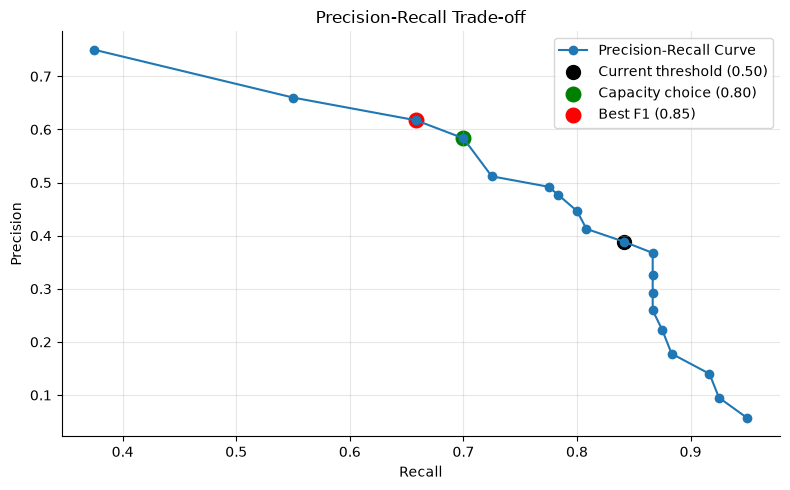

Recommendation: Use threshold 0.80 with 144 alerts, precision 58.33% and recall 70.00%.


In [5]:

rows = []

# TODO 1: Calculate metrics for each threshold
for th in np.round(np.arange(0.05, 1.0, 0.05), 2):

    flag = tx["detector_score"] >= th

    tp = int(
        (flag & (tx["is_fraud"] == 1)).sum()
    )

    fp = int(
        (flag & (tx["is_fraud"] == 0)).sum()
    )

    fn = int(
        (~flag & (tx["is_fraud"] == 1)).sum()
    )

    alerts = tp + fp

    precision = tp / alerts if alerts > 0 else 0

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0 else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    rows.append({
        "threshold": th,
        "alerts": alerts,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "precision": precision,
        "recall": recall,
        "F1": f1
    })

pr = pd.DataFrame(rows)

# TODO 2: Capacity-constrained choice
eligible = pr[pr["alerts"] <= 150]

capacity_choice = eligible.sort_values(
    ["recall", "F1"],
    ascending=False
).iloc[0]

# Best F1 threshold
best_f1 = pr.loc[pr["F1"].idxmax()]

print("Capacity-constrained choice:")
print(capacity_choice)

print("\nBest F1 choice:")
print(best_f1)

# TODO 3: Precision-recall curve
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    pr["recall"],
    pr["precision"],
    marker="o",
    label="Precision-Recall Curve"
)

# Current threshold
current = pr[pr["threshold"] == 0.50].iloc[0]

ax.scatter(
    current["recall"],
    current["precision"],
    color="black",
    s=100,
    label="Current threshold (0.50)"
)

# Capacity choice
ax.scatter(
    capacity_choice["recall"],
    capacity_choice["precision"],
    color="green",
    s=110,
    label="Capacity choice (0.80)"
)

# Best F1 choice
ax.scatter(
    best_f1["recall"],
    best_f1["precision"],
    color="red",
    s=110,
    label="Best F1 (0.85)"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Trade-off")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# TODO 4: Recommendation
print(
    f"Recommendation: Use threshold {capacity_choice['threshold']:.2f} "
    f"with {int(capacity_choice['alerts'])} alerts, "
    f"precision {capacity_choice['precision']:.2%} "
    f"and recall {capacity_choice['recall']:.2%}."
)


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_The Head of Fraud Ops should make the final threshold decision rather than allowing the model to decide independently. The capacity-constrained threshold of 0.80 achieves 70% recall while keeping the alert count within the team's limit of 150. The best-F1 threshold of 0.85 provides slightly higher F1 and precision but misses more fraud cases. Visual analytics keeps a human in the loop because operational capacity, investigation priorities and the consequences of missed fraud require human judgement, not just statistical optimisation.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:

# TODO 1: Interactive transaction scatter plot
flagged = tx[tx["detector_score"] >= 0.3].copy()

fig1 = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_name="txn_id",
    hover_data={
        "customer_id": True,
        "city": True,
        "merchant_category": True,
        "distance_from_home_km": ":.2f",
        "detector_score": ":.3f",
        "label": False,
        "timestamp": True
    },
    color_discrete_map={
        "legitimate": "steelblue",
        "confirmed fraud": "red"
    },
    title="Fraud Investigation: Flagged Transactions",
    height=550
)

fig1.update_layout(
    dragmode="select",
    xaxis_title="Transaction Timestamp",
    yaxis_title="Transaction Amount (INR)"
)

fig1.update_traces(marker_size=7)

fig1.show()

# TODO 2: Interactive Sunburst
agg = (
    tx.groupby(["city", "merchant_category"])
    .agg(
        transactions=("txn_id", "size"),
        fraud=("is_fraud", "sum")
    )
    .reset_index()
)

agg["fraud_rate_pct"] = (
    agg["fraud"] / agg["transactions"] * 100
)

fig2 = px.sunburst(
    agg,
    path=[
        px.Constant("All Cities"),
        "city",
        "merchant_category"
    ],
    values="transactions",
    color="fraud_rate_pct",
    color_continuous_scale="Reds",
    range_color=[0, 25],
    hover_data={
        "fraud": True,
        "transactions": True
    },
    title="Fraud Distribution: City to Merchant Category",
    height=600
)

fig2.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_Tooltips are useful for inspecting one transaction at a time, but investigating 400 flagged cases individually would be slow and frustrating. Investigators would have to hover over every point to understand the overall pattern. The interactive sunburst and scatter plot solve this problem by providing an overview of fraud distribution, allowing drill-down into cities and merchant categories, and providing details-on-demand when needed.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Fraud rate inside window: 37.38%
Fraud rate outside window: 1.48%
Chi-square p-value: 1.065e-136
Pune on other days: 1.85%
Other cities on days 18-20: 0.44%
Everything else: 1.54%


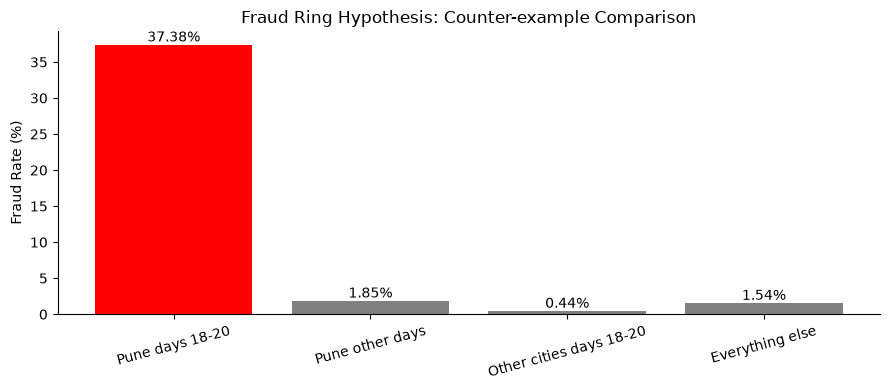

VERDICT: Strong statistical evidence of a localized fraud concentration in Pune during days 18-20. Investigate a possible coordinated fraud campaign.


In [7]:

from scipy.stats import chi2_contingency

# TODO 1: Define hypothesis window
in_window = (
    (tx["city"] == "Pune") &
    (tx["day"].between(18, 20))
)

# TODO 2: Fraud rate and chi-square test
table = pd.crosstab(
    in_window,
    tx["is_fraud"]
)

chi2, pval, _, _ = chi2_contingency(table)

inside_rate = tx.loc[in_window, "is_fraud"].mean()

outside_rate = tx.loc[~in_window, "is_fraud"].mean()

print(f"Fraud rate inside window: {inside_rate:.2%}")
print(f"Fraud rate outside window: {outside_rate:.2%}")
print(f"Chi-square p-value: {pval:.3e}")

# TODO 3: Counter-example searches
same_city_other_days = tx[
    (tx["city"] == "Pune") &
    (~tx["day"].between(18, 20))
]

other_cities_same_days = tx[
    (tx["city"] != "Pune") &
    (tx["day"].between(18, 20))
]

rest = tx[
    (tx["city"] != "Pune") &
    (~tx["day"].between(18, 20))
]

print(
    "Pune on other days:",
    f"{same_city_other_days['is_fraud'].mean():.2%}"
)

print(
    "Other cities on days 18-20:",
    f"{other_cities_same_days['is_fraud'].mean():.2%}"
)

print(
    "Everything else:",
    f"{rest['is_fraud'].mean():.2%}"
)

# TODO 4: Visual comparison of four groups
groups = {
    "Pune days 18-20": inside_rate,
    "Pune other days": same_city_other_days["is_fraud"].mean(),
    "Other cities days 18-20": other_cities_same_days["is_fraud"].mean(),
    "Everything else": rest["is_fraud"].mean()
}

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    groups.keys(),
    np.array(list(groups.values())) * 100,
    color=["red", "grey", "grey", "grey"]
)

ax.set_ylabel("Fraud Rate (%)")
ax.set_title("Fraud Ring Hypothesis: Counter-example Comparison")

ax.tick_params(axis="x", rotation=15)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# TODO 5: Verdict
if pval < 0.05 and inside_rate > outside_rate:
    print(
        "VERDICT: Strong statistical evidence of a localized "
        "fraud concentration in Pune during days 18-20. "
        "Investigate a possible coordinated fraud campaign."
    )
else:
    print(
        "VERDICT: Insufficient statistical evidence "
        "to support the fraud concentration hypothesis."
    )


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_Both counter-example searches are important. If Pune had similarly high fraud rates on other days, it would suggest a general city-specific fraud problem rather than a time-specific campaign. If other cities also showed high fraud rates on days 18–20, it would suggest a wider time-related issue rather than a Pune-specific event. Since both counter-example rates are low, the evidence supports a localized Pune fraud concentration. However, statistical significance alone does not prove that the transactions were carried out by a coordinated fraud ring.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_The review identified 120 confirmed fraud cases among 5,520 transactions, with a major concentration in Pune between days 18 and 20, where the fraud rate reached 37.38%. I recommend increasing the detector threshold from 0.50 to 0.80, producing 144 alerts within the team's monthly capacity, with 58.33% precision and 70% recall. The first interactive tool should be the Plotly transaction scatter dashboard with selection, filtering and hover details, following Shneiderman's overview-first and details-on-demand principles. The slider performance test should also guide the engineering team in maintaining the 0.1-second dynamic-query response budget when scaling to 50 million transactions. Finally, implement a human-in-the-loop feedback cycle in which investigators confirm or reject flagged transactions and their verified labels are fed back into the detector for retraining and improvement.